In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
tf.keras.preprocessing.image.ImageDataGenerator
import matplotlib.pyplot as plt
import cv2
import os,random,shutil

In [ ]:
from sklearn.model_selection import train_test_split
from keras.utils import to_categorical,load_img


In [ ]:


# قائمة بالمجلدات المراد حذفها نهائياً
folders_to_delete = [
    'data_train',
    'data_train_X',
    'data_train_X_2',
    'data_test',
    'data_test_y',
    'data_test_y_2'
]

for folder in folders_to_delete:
    if os.path.exists(folder):
        shutil.rmtree(folder)
        print(f"تم حذف المجلد: {folder}")
    else:
        print(f"المجلد غير موجود بالفعل: {folder}")

print("اكتملت عملية التنظيف!")

تم حذف المجلد: data_train
المجلد غير موجود بالفعل: data_train_X
المجلد غير موجود بالفعل: data_train_X_2
تم حذف المجلد: data_test
المجلد غير موجود بالفعل: data_test_y
المجلد غير موجود بالفعل: data_test_y_2
اكتملت عملية التنظيف!


In [ ]:
os.environ['KAGGLE_USERNAME'] = ""
os.environ['KAGGLE_KEY'] = ""

print("جاري تحميل داتا سيت Cats vs Dogs من كاجل ...")

!kaggle datasets download -d shaunthesheep/microsoft-catsvsdogs-dataset --unzip -p ./cats_dogs_data

print("اكتمل التحميل وفك الضغط بنجاح! البيانات جاهزة الآن في مجلد cats_dogs_data.")

جاري تحميل داتا سيت Cats vs Dogs من كاجل ...
Dataset URL: https://www.kaggle.com/datasets/shaunthesheep/microsoft-catsvsdogs-dataset
License(s): other
100% 788M/788M [00:11<00:00, 74.0MB/s]

اكتمل التحميل وفك الضغط بنجاح! البيانات جاهزة الآن في مجلد cats_dogs_data.


In [ ]:

# 1. إنشاء مجلدات الترين والتست الفرعية (مهم جداً لـ TensorFlow)
os.makedirs('data_train/cat', exist_ok=True)
os.makedirs('data_train/dog', exist_ok=True)
os.makedirs('data_test/cat', exist_ok=True)
os.makedirs('data_test/dog', exist_ok=True)

# 2. تحديد المسارات الأصلية
cat_dir = '/content/cats_dogs_data/PetImages/Cat'
dog_dir = "/content/cats_dogs_data/PetImages/Dog"

# 3. جلب قوائم الملفات وترتيبها وتصفيتها للتأكد من أنها صور فقط
cats = sorted([f for f in os.listdir(cat_dir) if f.endswith(('.jpg', '.jpeg', '.png'))])
dogs = sorted([f for f in os.listdir(dog_dir) if f.endswith(('.jpg', '.jpeg', '.png'))])

# 4. تقسيم البيانات (900 للتدريب و 150 للاختبار لكل نوع)
cats_train = cats[:900]
dogs_train = dogs[:900]

cats_test = cats[900:1050]
dogs_test = dogs[900:1050]

# 5. دمج وتجهيز القوائم مع تحديد الفئة (cat أو dog) ليوجهها الكود للمجلد الصحيح
train_pool = []
for f in cats_train: train_pool.append((f, cat_dir, f"cat.{f}", "cat"))
for f in dogs_train: train_pool.append((f, dog_dir, f"dog.{f}", "dog"))

test_pool = []
for f in cats_test:  test_pool.append((f, cat_dir, f"0_{f}", "cat"))
for i in dogs_test:  test_pool.append((i, dog_dir, f"1_{i}", "dog"))

# 6. عمل خلط عشوائي (Shuffle) للقوائم المدمجة
random.seed(42)
random.shuffle(train_pool)
random.shuffle(test_pool)

# 7. دالة لنسخ الملفات وتوجيهها تلقائياً للمجلد الفرعي المناسب (تم تعديلها هنا)
def copy_mixed_files(pool_list, destination_folder):
    for original_name, src_dir, new_name, category in pool_list:
        source_path = os.path.join(src_dir, original_name)
        # توجيه الملف إلى المجلد الفرعي الخاص به (cat أو dog)
        destination_path = os.path.join(destination_folder, category, new_name)

        if os.path.isfile(source_path):
            shutil.copy(source_path, destination_path)

# 8. تنفيذ عملية النسخ الفعلي في المجلدات المنظمة
print("جاري نسخ ملفات التدريب المختلطة وتصنيفها داخل المجلدات الفرعية...")
copy_mixed_files(train_pool, 'data_train')

print("جاري نسخ ملفات الاختبار المختلطة وتصنيفها داخل المجلدات الفرعية...")
copy_mixed_files(test_pool, 'data_test')

print(f"\n✅ تمت العملية بنجاح! ملفات الترين جاهزة في 'data_train' وملفات التست في 'data_test' داخل مجلدات فرعية.")

جاري نسخ ملفات التدريب المختلطة وتصنيفها داخل المجلدات الفرعية...
جاري نسخ ملفات الاختبار المختلطة وتصنيفها داخل المجلدات الفرعية...

✅ تمت العملية بنجاح! ملفات الترين جاهزة في 'data_train' وملفات التست في 'data_test' داخل مجلدات فرعية.


In [ ]:
NUM_CLASSES=2
CHANNELS=3
IMAGE_RESIZE=224
RESNET50_POOLING_AVERAGE='Avg'
DENSE_LAYER_ACTIVATION='softmax'
OBJECTIVE_FUNCTION='categorical_crossentoropy'
LOSS_METRICS=['accuracy']
NUM_EPOCHS=10
EARLY_STOP_PATIENCE=3
STEPS_PER_EPOCH_TRAINNG=10
STEPS_PER_EPOCH_VALIDIATION=10
BATCH_SIZE_TRAINNGE=100
BATCH_SIZE_VALIDATION=100
BATCH_SIZE_TESTING=1

In [ ]:

def remove_corrupted_images(root_dir):
    deleted_count = 0
    # المرور على جميع المجلدات والملفات بالداخل
    for root, dirs, files in os.walk(root_dir):
        for file in files:
            file_path = os.path.join(root, file)
            # استبعاد الملفات المخفية والنظامية مثل .config أو readme
            if file.startswith('.') or not file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                os.remove(file_path)
                deleted_count += 1
                continue

            # محاولة قراءة الصورة للتأكد من سلامتها
            img = cv2.imread(file_path)
            if img is None: # إذا لم ينجح بايثون في فتحها كصورة حقيقية
                print(f"جاري حذف ملف تالف أو غير مدعوم: {file_path}")
                os.remove(file_path)
                deleted_count += 1
    print(f"✅ فحص مجلد {root_dir} مكتمل. تم حذف {deleted_count} ملفات معطوبة.")

# تنفيذ التصفية على مجلداتك
remove_corrupted_images('data_train')
remove_corrupted_images('data_test')

جاري حذف ملف تالف أو غير مدعوم: data_train/cat/cat.10404.jpg
✅ فحص مجلد data_train مكتمل. تم حذف 1 ملفات معطوبة.
✅ فحص مجلد data_test مكتمل. تم حذف 0 ملفات معطوبة.


In [ ]:
import tensorflow as tf
from keras.applications.resnet50 import preprocess_input

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data_train",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMAGE_RESIZE,
    batch_size=BATCH_SIZE_TRAINNGE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data_train",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMAGE_RESIZE,
    batch_size=BATCH_SIZE_VALIDATION
)

train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))


Found 1799 files belonging to 2 classes.
Using 1440 files for training.
Found 1799 files belonging to 2 classes.
Using 359 files for validation.


In [ ]:

from tensorflow.keras.applications import ResNet50

# تحميل النموذج بأوزان الإيميج نت الجاهزة مباشرة
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

print("تم تحميل نموذج ريزنت 50 بنجاح من خوادم TensorFlow!")

تم تحميل نموذج ريزنت 50 بنجاح من خوادم TensorFlow!


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Flatten, Dropout

# 1. بناء طبقات الأوجمنتيشن (Data Augmentation Layers)
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.1),])

base_model = ResNet50(include_top=False, weights='imagenet', input_shape=(IMAGE_RESIZE,IMAGE_RESIZE,CHANNELS))
base_model.trainable = False
model = Sequential([
    layers.Input(shape=(IMAGE_RESIZE, IMAGE_RESIZE, CHANNELS)),
    data_augmentation,
    base_model,
    Flatten(),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation=DENSE_LAYER_ACTIVATION)])

model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True),
    loss='sparse_categorical_crossentropy',
    metrics=LOSS_METRICS
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_4 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │       200,706 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,788,418 (90.75 MB)

 Trainable params: 200,706 (784.01 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
(BATCH_SIZE_TRAINNGE,len(train_ds),BATCH_SIZE_VALIDATION,len(val_ds))

(100, 15, 100, 4)

In [ ]:
from keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping,ModelCheckpoint

In [ ]:
cb_early_stopper=EarlyStopping(monitor='val_loss',patience=EARLY_STOP_PATIENCE)
cb_check_point=ModelCheckpoint(filepath="/content/best_model.keras",monitor='val_loss',save_best_only=True,mode='auto')

In [ ]:
fit_history=model.fit(train_ds,steps_per_epoch=STEPS_PER_EPOCH_TRAINNG,
                      epochs=NUM_EPOCHS,
                      validation_data=val_ds,
                      validation_steps=STEPS_PER_EPOCH_VALIDIATION,
                      callbacks=[cb_check_point,cb_early_stopper])

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.6512 - loss: 40.7392

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.7470 - loss: 40.3690 - val_accuracy: 0.9638 - val_loss: 7.7026
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 625ms/step - accuracy: 0.8932 - loss: 16.2710 - val_accuracy: 0.9721 - val_loss: 8.5557
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 882ms/step - accuracy: 0.8870 - loss: 21.0287 - val_accuracy: 0.9694 - val_loss: 5.4375
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 476ms/step - accuracy: 0.9000 - loss: 18.0785 - val_accuracy: 0.9777 - val_loss: 4.3888
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 757ms/step - accuracy: 0.9040 - loss: 16.0948 - val_accuracy: 0.9666 - val_loss: 4.6703
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 487ms/step - accuracy: 0.8955 - loss: 17.3054 - val_accuracy: 0.9749 - val_loss: 3.7758
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 16s 771ms/step - accuracy: 0.9000 - loss: 17.4400 - val_accuracy: 0.9805 - val_loss: 3.7408
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 538ms/step - accuracy: 0.9136 - loss: 17.5775 - val_accuracy: 0.9805

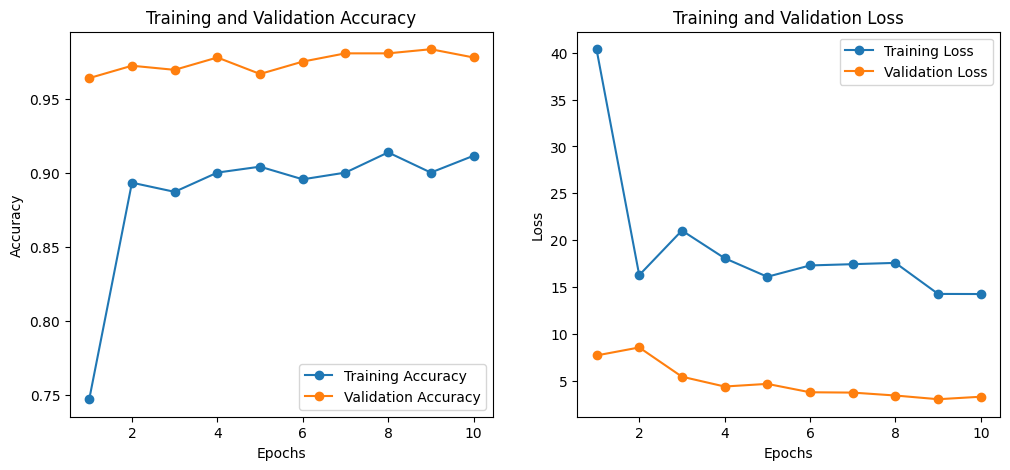

In [ ]:
import matplotlib.pyplot as plt

# جلب بيانات الدقة والخطأ من متغير fit_history
acc = fit_history.history['accuracy']
val_acc = fit_history.history['val_accuracy']
loss = fit_history.history['loss']
val_loss = fit_history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# رسم دقة التدريب مقابل دقة التحقق
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# رسم نسبة خطأ التدريب مقابل خطأ التحقق
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

Found 300 files belonging to 2 classes.
جاري حساب التوقعات للنموذج...
300/300 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step


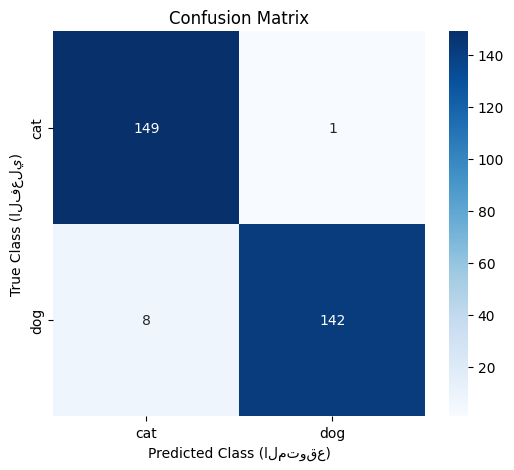


📊 تقرير الأداء التفصيلي (Classification Report):
              precision    recall  f1-score   support

         cat       0.95      0.99      0.97       150
         dog       0.99      0.95      0.97       150

    accuracy                           0.97       300
   macro avg       0.97      0.97      0.97       300
weighted avg       0.97      0.97      0.97       300



In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/data_test",
    shuffle=False,
    image_size=IMAGE_RESIZE,
    batch_size=BATCH_SIZE_TESTING
)

# الحصول على الأسماء الحقيقية للكلاسات (مثل ['cat', 'dog'])
class_names = test_ds.class_names

# تطبيق نفس المعالجة المسبقة لـ ResNet50
test_ds_processed = test_ds.map(lambda x, y: (preprocess_input(x), y))

# 3. استخراج الإجابات الحقيقية (True Labels) من البيانات الأصلية
y_true = np.concatenate([y for x, y in test_ds], axis=0)

# 4. جعل النموذج يقوم بالتنبؤ (Predictions) على صور الاختبار
print("جاري حساب التوقعات للنموذج...")
y_pred_probs = model.predict(test_ds_processed)

# تحويل الاحتمالات الصادرة من softmax إلى أرقام كلاسات (0 أو 1) بناءً على القيمة الأعلى
y_pred = np.argmax(y_pred_probs, axis=0) if y_pred_probs.ndim == 1 or y_pred_probs.shape[1] == 1 else np.argmax(y_pred_probs, axis=1)

# 5. حساب مصفوفة الارتباك
cm = confusion_matrix(y_true, y_pred)

# 6. رسم مصفوفة الارتباك بشكل مرئي واحترافي باستخدام Seaborn Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix')
plt.ylabel('True Class (الفعلي)')
plt.xlabel('Predicted Class (المتوقع)')
plt.show()

# 7. طباعة تقرير التصنيف الشامل (Precision, Recall, F1-Score)
print("\n📊 تقرير الأداء التفصيلي (Classification Report):")
print(classification_report(y_true, y_pred, target_names=class_names))

In [ ]:
from google.colab import files

# 1. حفظ النموذج بالكامل بصيغة كيرات القياسية الحديثة
model_save_path = "/content/cats_and_dogs_resnet50.keras"
model.save(model_save_path)
print("✅ تم حفظ النموذج بنجاح داخل بيئة Colab.")

# 2. بدء تحميل الملف مباشرة إلى جهاز الكمبيوتر الخاص بك
print("جاري تجهيز تحميل الملف إلى جهازك، انتظر ثوانٍ...")
files.download(model_save_path)

✅ تم حفظ النموذج بنجاح داخل بيئة Colab.
جاري تجهيز تحميل الملف إلى جهازك، انتظر ثوانٍ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from keras.applications.resnet50 import preprocess_input

# 1. استدعاء النموذج المحفوظ من مساره (ضع مسار الملف على جهازك هنا)
# ملحوظة: في بيئة العمل الجديدة، ستقوم فقط برفع هذا الملف وتشغيل السطر التالي:
my_model = tf.keras.models.load_model('cats_and_dogs_resnet50.keras')

print("✅ تم تحميل نموذج ريزنت 50 بنجاح وهو جاهز للتنبؤ الآن!")

# 2. دالة التنبؤ المباشرة لأي صورة جديدة
def predict_new_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    # المعالجة الخاصة بـ ResNet50
    processed_img = preprocess_input(img_array)

    # حساب الاحتمالات
    predictions = my_model.predict(processed_img)

    class_names = ['Cat', 'Dog']
    predicted_class = class_names[np.argmax(predictions)]
    confidence = np.max(predictions) * 100

    print(f"🔮 نتيجة فحص الصورة: {predicted_class} (نسبة الثقة: {confidence:.2f}%)")

# 3. لتشغيل الدالة، فقط ضَع مسار أي صورة تريد فحصها:
# predict_new_image("مسار_صورة_جديدة.jpg")

✅ تم تحميل نموذج ريزنت 50 بنجاح وهو جاهز للتنبؤ الآن!
